# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

**Topology (tested, not assumed).** The malignant manifold is a diffuse, roughly round cloud
(UMAP major/minor ≈ 1.4). We test branching **honestly**: fit an scFates PPT **tree** across a
parameter grid *and* render its fork/tip nodes on the embedding, alongside an ElPiGraph **curve**.
The tree's fork count is unstable across parameters (1–4 forks that jump position) — the signature
of spurious forks a tree threads through a 2-D cloud, **not** a reproducible bifurcation. The curve
gives a stable, fold-free single backbone. So the correct topology is a **principal curve**
(non-branching), fit on the *joint* embedding — **not** a re-embedding (re-embedding an anisotropic
compartment fabricates folds; Kürten §4). The curve is rooted at the **gastrulation-high** tip (developmental origin: gastrulation is the earliest
program). On *this* dataset pSom (somitogenesis) is LOW at the root and rises to the terminus, and neural crest
is ELEVATED at the root rather than terminal (the Gate-2 inversion). Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
import re
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold; scores already computed + smoothed in 01
We keep all cells on their original joint-embedding coordinates (no re-embedding). The three
embryonic signatures were scored in 01 against the shared **union** pool and graph-smoothed for
geography (raw scores are shown in the 03 deliverables; smoothing is for reading geography only).

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP major/minor singular ratio: {s[0]/s[1]:.2f}  (roundish cloud, not an elongated strip)')
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed spatial correlations:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
sub = adata

whole malignant manifold: 360 cells on the joint embedding
UMAP major/minor singular ratio: 1.49  (roundish cloud, not an elongated strip)
raw module means (honest readout): {'Gast': -0.22, 'pSom': 0.1058, 'Crest': -0.0665}
smoothed spatial correlations:
  Gast_sm vs pSom_sm: r = +0.04
  Crest_sm vs Gast_sm: r = +0.44
  Crest_sm vs pSom_sm: r = +0.10


### Honest branching test — PPT tree vs curve
`fold_diag` measures a curve's minimum self-approach: the smallest distance between graph-non-adjacent
nodes in units of median edge length (>1 = fold-free). We fit a PPT tree across `Nodes × λ` and count
forks (degree ≥ 3 nodes); a **genuine** bifurcation is stable across parameters.

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks

print('PPT TREE fork count across parameters (stable forks = genuine bifurcation):')
for Nn in [15,20,30]:
    for lam in [1.0, 5.0]:
        a = sub.copy()
        with contextlib.redirect_stdout(io.StringIO()):
            scf.tl.tree(a, Nodes=Nn, use_rep='X_umap', method='ppt', ppt_lambda=lam, ppt_sigma=0.5, seed=SEED, plot=False)
        Bt = np.asarray(a.uns['graph']['B'])
        print(f'  PPT N={Nn} lambda={lam}: {int(((Bt>0).sum(0)==1).sum())} tips, {int(((Bt>0).sum(0)>=3).sum())} forks')
print('CURVE fold self-approach across node counts (>1 = fold-free):')
for Nn in [15,20,30]:
    a = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa,tips,forks = fold_diag(a)
    print(f'  curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
print('-> tree forks jump 1-4 across params (spurious in a diffuse cloud); curve is a stable fold-free',
      'single backbone -> NON-BRANCHING. Fit a curve.')

PPT TREE fork count across parameters (stable forks = genuine bifurcation):
  PPT N=15 lambda=1.0: 3 tips, 1 forks
  PPT N=15 lambda=5.0: 5 tips, 3 forks
  PPT N=20 lambda=1.0: 5 tips, 3 forks
  PPT N=20 lambda=5.0: 4 tips, 2 forks
  PPT N=30 lambda=1.0: 5 tips, 3 forks
  PPT N=30 lambda=5.0: 6 tips, 4 forks
CURVE fold self-approach across node counts (>1 = fold-free):
  curve N=15: 2 tips, 0 forks | self-approach 3.00
  curve N=20: 2 tips, 0 forks | self-approach 2.97
  curve N=30: 2 tips, 0 forks | self-approach 2.43
-> tree forks jump 1-4 across params (spurious in a diffuse cloud); curve is a stable fold-free single backbone -> NON-BRANCHING. Fit a curve.


### Render fitted tree vs curve edges on the embedding (topology shown, not asserted)
The Chen-2020 attempt-5 failure was calling a manifold non-branching on a metric alone; the
attempt-6 failure was a folded curve hidden because edges were never drawn. So we draw both: the
tree's forks (red) scatter to different positions per parameter set; the curve is one clean arc.

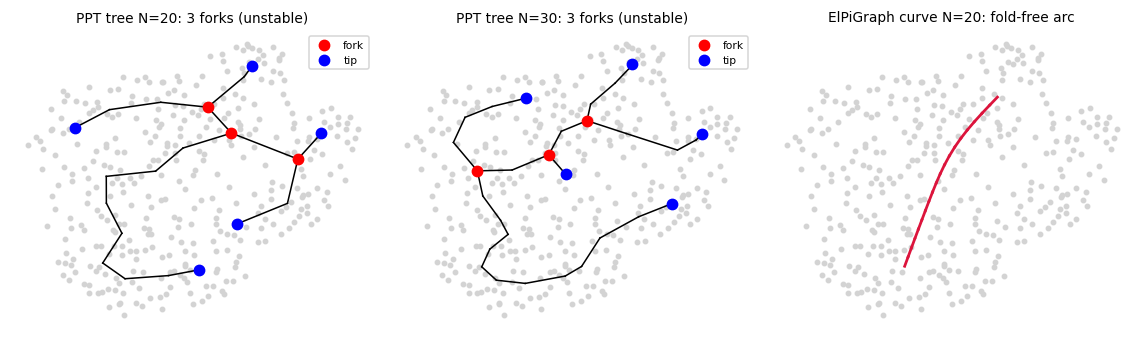

In [ ]:
def edges(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    ii,jj = np.where(np.triu(B>0)); return F, list(zip(ii,jj)), (B>0).sum(0)
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2))
for ax,(Nn,lam) in zip(axes[:2], [(20,1.0),(30,1.0)]):
    a = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a, Nodes=Nn, use_rep='X_umap', method='ppt', ppt_lambda=lam, ppt_sigma=0.5, seed=SEED, plot=False)
    F,E,deg = edges(a)
    ax.scatter(xy[:,0], xy[:,1], s=8, c='lightgray')
    for i,j in E: ax.plot([F[i,0],F[j,0]],[F[i,1],F[j,1]],'-',c='k',lw=1)
    ax.scatter(F[deg>=3,0],F[deg>=3,1],c='red',s=45,zorder=5,label='fork')
    ax.scatter(F[deg==1,0],F[deg==1,1],c='blue',s=45,zorder=5,label='tip')
    ax.set_title(f'PPT tree N={Nn}: {int((deg>=3).sum())} forks (unstable)', size=9); ax.axis('off'); ax.legend(fontsize=7)
a = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(a, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
F,E,deg = edges(a)
axes[2].scatter(xy[:,0], xy[:,1], s=8, c='lightgray')
for i,j in E: axes[2].plot([F[i,0],F[j,0]],[F[i,1],F[j,1]],'-',c='crimson',lw=1.8)
axes[2].set_title('ElPiGraph curve N=20: fold-free arc', size=9); axes[2].axis('off')
fig.tight_layout(); plt.show()

### Fit the committed curve, derive the root, infer pseudotime
Root = the curve tip with the higher gastrulation (Gast) score = the developmental origin (gastrulation is the earliest
program; the Gast+pSom-Crest heuristic selects the same tip). Pseudotime then flows toward the pSom-high terminus. We
print the actual root-vs-terminus biology (Gast high, pSom low, Crest elevated = the inversion) and the cell-cycle caveat.

In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'committed curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '-- biology at root: Gast HIGH (developmental origin), pSom LOW, Crest ELEVATED (Gate-2 inversion)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for smod in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[smod]); print(f'  {smod}: rho={rho:+.3f} p={p:.1e}')
for m,lab in [('Gast_sm','Gastrulation'),('pSom_sm','Somitogenesis'),('Crest_sm','Neural-crest')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
rho_c,_ = spearmanr(t, np.maximum(g1s, g2m))
print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} (axis is developmental, not proliferation-driven)')

committed curve: 2 tips, 0 forks | fold self-approach ratio = 2.97 (>1 = fold-free)
tip 0: Gast=-0.2086 pSom=+0.0945 Crest=-0.0488
tip 2: Gast=-0.2442 pSom=+0.1003 Crest=-0.0643
derived root = tip 0 -- biology at root: Gast HIGH (developmental origin), pSom LOW, Crest ELEVATED (Gate-2 inversion)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.777 p=7.8e-74
  pSom_sm: rho=+0.313 p=1.2e-09
  Crest_sm: rho=-0.607 p=1.3e-37
Gastrulation-high decile mean pseudotime = 0.12
Somitogenesis-high decile mean pseudotime = 0.88
Neural-crest-high decile mean pseudotime = 0.19
caveat: pseudotime vs cycling score rho = +0.18 (axis is developmental, not proliferation-driven)


### Confirm house orientation (pseudotime origin → left)
Orientation was fixed in 01 by a rigid rotation of the raw UMAP (no re-embedding). Here we only
verify that low pseudotime lands on the left of `X_umap_lin`; flip the sign if not.

In [ ]:
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
print(f'corr(x_lin, pseudotime) = {r:+.2f} (origin on left, terminus on right)')
assert r > 0.3, f'orientation not pseudotime-consistent (corr={r:.2f})'

corr(x_lin, pseudotime) = +0.98 (origin on left, terminus on right)


### Save manifold + trajectory figure (deliverable `manifold.pdf`)

saved manifold.h5ad + manifold.pdf


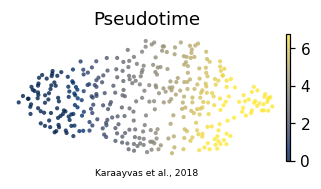

In [ ]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Karaayvas et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf')